# 02 — Fusion tuning and error analysis

How the fusion weight `alpha` and the thresholds were chosen on the validation set, and how the three systems (ML only, rules only, hybrid) behave on the test set.
Individual messages are not shown here; the anonymized error examples are in [`reports/error_analysis.md`](../reports/error_analysis.md).

Reproduce: download + build the dataset, `python scripts/train.py`, `python scripts/evaluate.py`, then run all cells.

In [1]:
import json
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd

from smishguard import config
from smishguard.analyzer import Analyzer
from smishguard.evaluation import tune_threshold
from smishguard.features.reasons import evaluate_rules, rule_score
from smishguard.metrics import classification_metrics
from smishguard.model.predict import predict_proba

analyzer = Analyzer.from_files()
params = analyzer.params


def score(name: str) -> pd.DataFrame:
    data = pd.read_csv(config.PROCESSED_DIR / f"{name}.csv", keep_default_na=False)
    prepared = data["text"].map(analyzer.prepare)
    reasons = prepared.map(evaluate_rules)
    return data.assign(
        ml=predict_proba(analyzer.model, prepared),
        rules=reasons.map(rule_score),
        codes=reasons.map(lambda rs: [r.code for r in rs]),
    )


val, test = score("val"), score("test")
params

FusionParams(alpha=0.9, medium_threshold=0.5, high_threshold=0.65)

## Alpha sweep on validation

For every `alpha`, the best decision threshold is searched; the table shows the best F1 each alpha can reach. `alpha = 1.0` (ML only) and `0.0` (rules only) are added for reference although they are outside the tuning grid.

In [2]:
rows = []
for alpha in (1.0, *config.ALPHA_GRID, 0.0):
    fused = alpha * val["ml"] + (1 - alpha) * val["rules"]
    best = tune_threshold(val["label"], fused)
    rows.append(
        {
            "alpha": alpha,
            "threshold": best.threshold,
            "f1": best.metrics["f1"],
            "precision": best.metrics["precision"],
            "recall": best.metrics["recall"],
            "fpr": best.metrics["false_positive_rate"],
        }
    )
sweep = pd.DataFrame(rows)
sweep

,alpha,threshold,f1,precision,recall,fpr
0,1.0,0.55,0.9800,1.0000,0.9608,0.0000
1,0.9,0.50,0.9800,1.0000,0.9608,0.0000
2,0.8,0.45,0.9800,1.0000,0.9608,0.0000
3,0.7,0.30,0.9623,0.9273,1.0000,0.0656
4,0.6,0.35,0.9608,0.9608,0.9608,0.0328
5,0.5,0.20,0.9533,0.9107,1.0000,0.0820
6,0.4,0.15,0.9444,0.8947,1.0000,0.0984
7,0.3,0.15,0.9423,0.9245,0.9608,0.0656
8,0.0,0.05,0.8387,0.9286,0.7647,0.0492


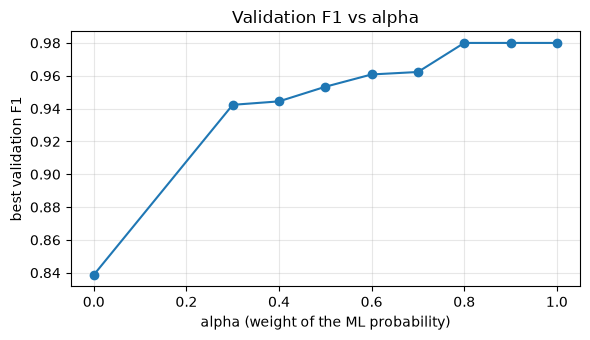

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(sweep["alpha"], sweep["f1"], marker="o")
ax.set_xlabel("alpha (weight of the ML probability)")
ax.set_ylabel("best validation F1")
ax.set_title("Validation F1 vs alpha")
ax.grid(alpha=0.3)
plt.tight_layout()

## Threshold curve for the chosen alpha (validation)

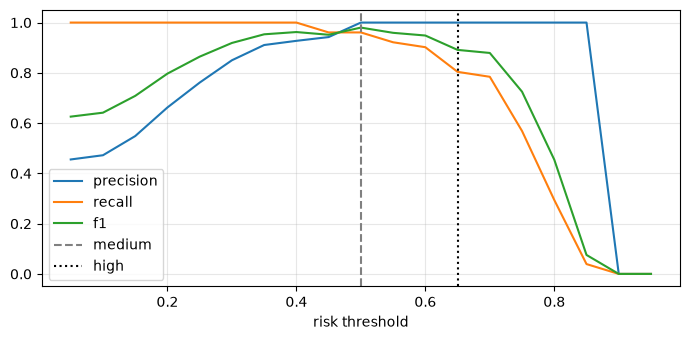

In [4]:
fused_val = params.alpha * val["ml"] + (1 - params.alpha) * val["rules"]
curve = pd.DataFrame(
    [
        {"threshold": t, **classification_metrics(val["label"], (fused_val >= t).astype(int))}
        for t in config.THRESHOLD_GRID
    ]
)
fig, ax = plt.subplots(figsize=(7, 3.5))
for metric in ("precision", "recall", "f1"):
    ax.plot(curve["threshold"], curve[metric], label=metric)
ax.axvline(params.medium_threshold, color="grey", linestyle="--", label="medium")
ax.axvline(params.high_threshold, color="black", linestyle=":", label="high")
ax.set_xlabel("risk threshold")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()

## Score distributions on the test set

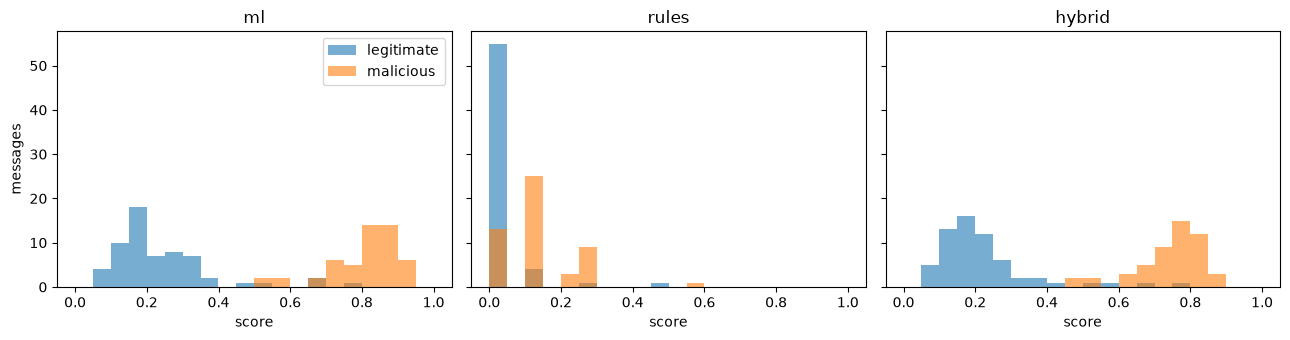

In [5]:
test["hybrid"] = params.alpha * test["ml"] + (1 - params.alpha) * test["rules"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), sharey=True)
for ax, column in zip(axes, ("ml", "rules", "hybrid"), strict=True):
    for label, name in ((0, "legitimate"), (1, "malicious")):
        ax.hist(
            test.loc[test["label"] == label, column], bins=20, range=(0, 1), alpha=0.6, label=name
        )
    ax.set_title(column)
    ax.set_xlabel("score")
axes[0].set_ylabel("messages")
axes[0].legend()
plt.tight_layout()

## Which rules fire on the test set?

In [6]:
counts = {
    name: Counter(code for codes in test.loc[test["label"] == label, "codes"] for code in codes)
    for label, name in ((0, "legitimate"), (1, "malicious"))
}
pd.DataFrame(counts).fillna(0).astype(int).sort_values("malicious", ascending=False)

,legitimate,malicious
MONEY_OR_FINE,3,32
URGENCY_LANGUAGE,2,9
PRIZE_CLAIM,0,7
CREDENTIAL_REQUEST,2,1


## Final test metrics (from `reports/metrics_test.json`)

In [7]:
report = json.loads(config.TEST_METRICS_PATH.read_text(encoding="utf-8"))
pd.DataFrame(
    {
        system: {
            **{k: r["metrics"][k] for k in ("precision", "recall", "f1", "false_positive_rate")},
            "f1_ci95": r["f1_ci95"],
        }
        for system, r in report["test"].items()
    }
).T

,precision,recall,f1,false_positive_rate,f1_ci95
ml_only,0.9423,0.9608,0.9515,0.0492,"[0.9032, 0.9903]"
rules_only,0.8636,0.7451,0.8,0.0984,"[0.7021, 0.8843]"
hybrid,0.9245,0.9608,0.9423,0.0656,"[0.8846, 0.9825]"


## Findings

- **Alpha:** validation F1 is flat (0.98) for alpha 0.81.0 and drops as the rules get more weight. The tie-break (lower FPR, then higher alpha) picks **alpha = 0.9**, the top of the planned grid, so the hybrid score is essentially the ML probability plus a small rule nudge.
- **Levels:** the medium threshold is 0.50 (best F1 on validation). The high threshold is 0.65: the first value precise enough on validation was lower, but the configured floor keeps a meaningful medium band.
- **Test (used once):** ML only F1 0.952, hybrid 0.942, rules only 0.800. ML and hybrid differ by one message, and their 95% bootstrap intervals overlap almost completely, so the data cannot rank them.
- **Rule coverage:** on the test set **no URL rule fires at all**, only text rules (mostly `MONEY_OR_FINE`). The real test messages contain no modern phishing links, so the URL half of the rule engine is only exercised by synthetic examples and unit tests. It is kept because it explains the scam patterns that matter today, not because it improves these metrics.